In [5]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

df = pd.read_csv('compras_ecommerce.csv')

display(df.head())

,ID_Transaccion,Producto
0,TKT-00181,Teclado Mecánico RGB
1,TKT-01162,"Monitor 27"" 144Hz"
2,TKT-00840,Silla Gamer Ergonómica
3,TKT-01734,silla gamer ergonómica
4,TKT-01899,Mousepad XL


In [7]:
#Fase 1
df.dropna(subset=['Producto'], inplace=True)
df['Producto'] = df['Producto'].str.strip().str.upper()

df = df[df['ID_Transaccion'] != 'ERR_TIMEOUT']

df = df.drop_duplicates(subset=['ID_Transaccion', 'Producto'], keep='first')
display(df.head())
df.describe()

,ID_Transaccion,Producto
0,TKT-00181,TECLADO MECÁNICO RGB
1,TKT-01162,"MONITOR 27"" 144HZ"
2,TKT-00840,SILLA GAMER ERGONÓMICA
3,TKT-01734,SILLA GAMER ERGONÓMICA
4,TKT-01899,MOUSEPAD XL


,ID_Transaccion,Producto
count,6258,6258
unique,2494,10
top,TKT-00960,WEBCAM 1080P
freq,4,939


In [8]:
#Fase 2
pares = pd.merge(df, df, on='ID_Transaccion')

pares = pares[pares['Producto_x'] < pares['Producto_y']]

aristas = pares.groupby(['Producto_x', 'Producto_y']).size().reset_index(name='Peso')
aristas = aristas.sort_values('Peso', ascending=False)
display(aristas.head())

,Producto_x,Producto_y,Peso
8,AUDÍFONOS BLUETOOTH,WEBCAM 1080P,364
38,MOUSE INALÁMBRICO,WEBCAM 1080P,361
40,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
31,"MONITOR 27"" 144HZ",MOUSEPAD XL,358
23,LAPTOP PRO 15,WEBCAM 1080P,351


{'AUDÍFONOS BLUETOOTH': 1.0, 'WEBCAM 1080P': 1.0, 'MOUSE INALÁMBRICO': 1.0, 'MOUSEPAD XL': 1.0, 'TECLADO MECÁNICO RGB': 1.0, 'MONITOR 27" 144HZ': 1.0, 'LAPTOP PRO 15': 1.0, 'SILLA GAMER ERGONÓMICA': 1.0, 'MICRÓFONO DE CONDENSADOR': 1.0, 'CABLE HDMI 2.1': 1.0}
WEBCAM 1080P                1721
MONITOR 27" 144HZ           1648
TECLADO MECÁNICO RGB        1252
MOUSE INALÁMBRICO           1226
MOUSEPAD XL                 1214
LAPTOP PRO 15               1170
AUDÍFONOS BLUETOOTH         1167
SILLA GAMER ERGONÓMICA      1167
MICRÓFONO DE CONDENSADOR     697
CABLE HDMI 2.1               246
dtype: int64
Producto Ancla: WEBCAM 1080P


,Producto_x,Producto_y,Peso
40,MOUSEPAD XL,TECLADO MECÁNICO RGB,359
42,SILLA GAMER ERGONÓMICA,TECLADO MECÁNICO RGB,351
33,"MONITOR 27"" 144HZ",TECLADO MECÁNICO RGB,350
37,MOUSE INALÁMBRICO,TECLADO MECÁNICO RGB,37
44,TECLADO MECÁNICO RGB,WEBCAM 1080P,34


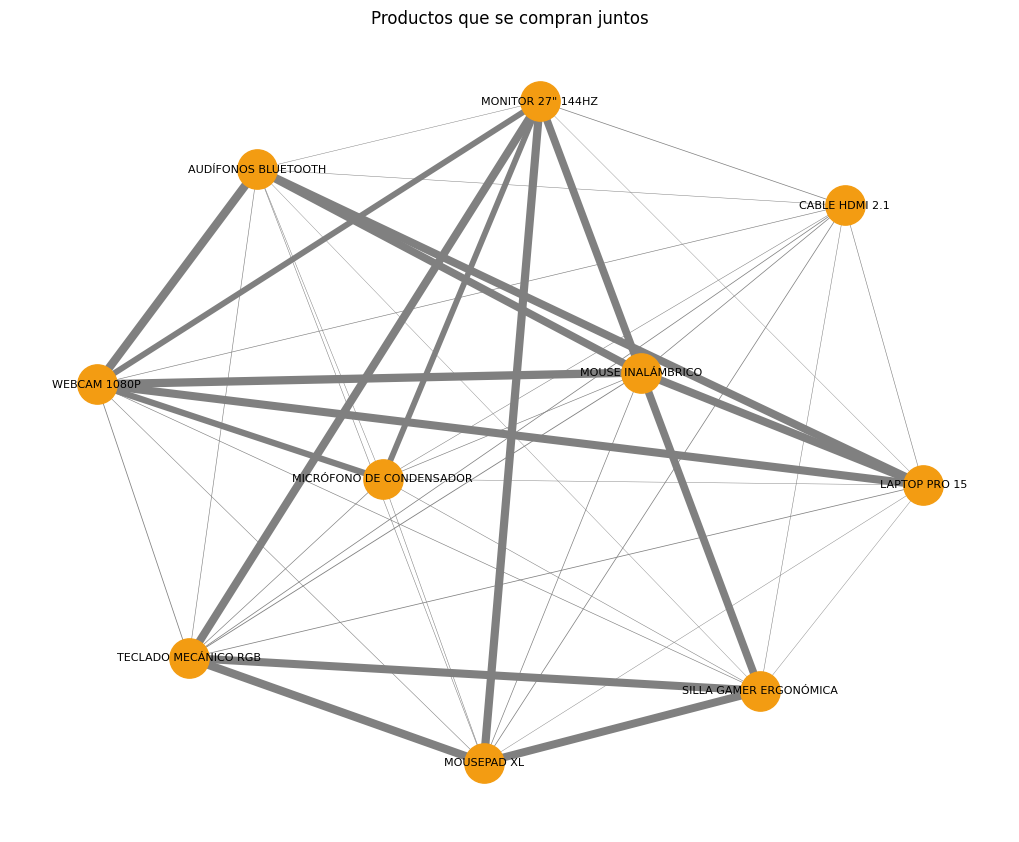

In [ ]:
#Fase 3
G = nx.from_pandas_edgelist(aristas, source='Producto_x', target='Producto_y', edge_attr='Peso')

centralidad = nx.degree_centrality(G)
print(centralidad)

peso_total = pd.Series(dict(G.degree(weight='Peso'))).sort_values(ascending=False)
print(peso_total)
print(f"Producto Ancla: {peso_total.index[0]}")

teclado = aristas[(aristas['Producto_x'] == 'TECLADO MECÁNICO RGB') | (aristas['Producto_y'] == 'TECLADO MECÁNICO RGB')]
display(teclado.head())

pesos = np.array(list(nx.get_edge_attributes(G, 'Peso').values()))

plt.figure(figsize=(10,8))
nx.draw(G, with_labels=True, node_color='#F39C12', node_size=800, font_size=8, width=pesos / pesos.max() * 6, edge_color='gray')
plt.title('Productos que se compran juntos')
plt.show()

¿Cuál es el Producto Ancla y qué se le recomienda a quien compra un TECLADO MECÁNICO RGB?
Con degree centrality todos los productos salen con 1.0 porque todos se compraron alguna vez con todos, por eso se desempató con los pesos y el producto ancla es la webcam 1080P. Si un cliente mete un teclado mecanico RGB al carrito se le debe recomendar el mousepad xl porque es con el que más se compra junto.